# Exercise: Image Manipulation in OpenCV

---

Prof. Dr.-Ing. Antje Muntzinger, Hochschule für Technik Stuttgart

antje.muntzinger@hft-stuttgart.de

---

In this notebook, we practice some basic image manipulation techniques in OpenCV. These are the foundation of later computer vision applications. Your tasks are the following: 

- Examine the image shape
- Split the three color channels
- Flip the image horizontally and vertically
- Draw on the image
- Resize the image

In [1]:
# imports
import cv2
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

## 1. Data Acquision

**TODO:** Make sure the image below is loaded and displayed correctly. You don't have to change the code, but make sure your image is correctly named and placed in a subfolder called `images` of the working directory.

In [2]:
# load image
input_img = cv2.imread('images/san_francisco_bay.jpg') 

# convert image to RGB and grayscale (matplotlib uses RGB, OpenCV uses BGR)
img_RGB = cv2.cvtColor(input_img, cv2.COLOR_BGR2RGB)
img_gray = cv2.cvtColor(input_img, cv2.COLOR_BGR2GRAY)

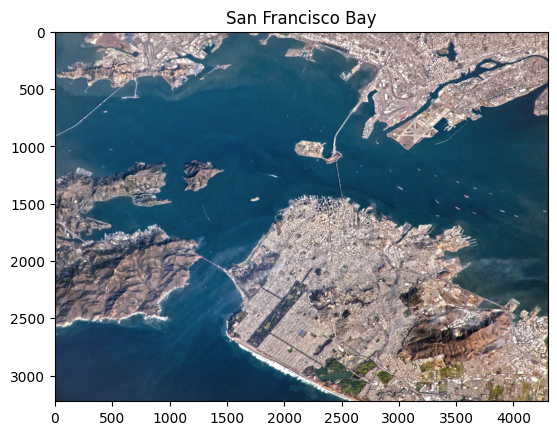

In [3]:
# display image
plt.imshow(img_RGB)
plt.title('San Francisco Bay')
plt.show()

## 2. Image Manipulation and Preprocessing

**TODO**: Find out the size of the image using the `shape` attribute of the image array and print it. Note that images in OpenCV are basically numpy arrays. How do you interpret the output?

In [10]:
# YOUR CODE GOES HERE

img_RGB.shape

(3224, 4299, 3)

**YOUR ANSWER**:

- 3224 x/j
- 4299 y/i
- 3 dimensions z of color

**TODO**: Split the image in the three color channels and plot them separately in matplotlib as grayscale images. You can use OpenCV's split function (see for example here: https://josephstreeter.github.io/docs/development/python/computer-vision/index.html) Can you see from the images which color channel is which?

**HINT:** Use `cmap = 'gray'` in `imshow` to display the channels correctly as grayscale images. In case you want to plot several images without `plt.subplots`, use `plt.show()` after each `plt.imshow` command (otherwise only the last image is displayed).

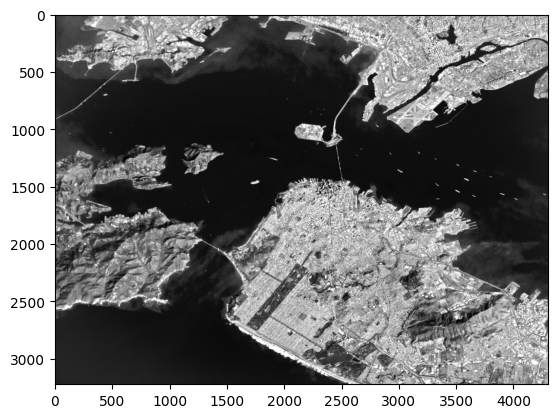

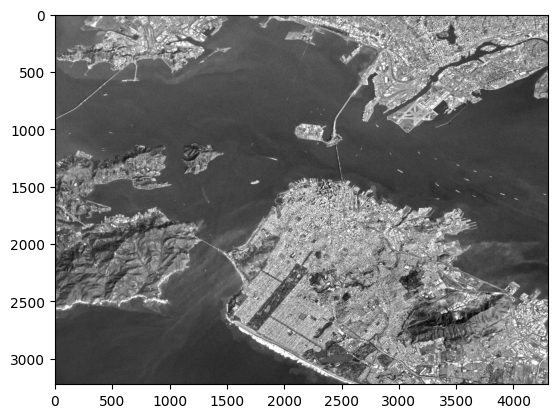

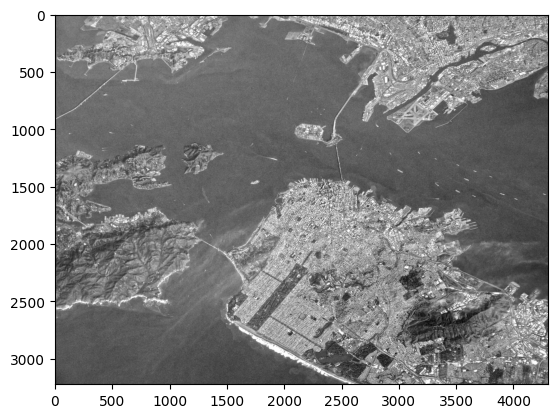

In [12]:
# YOUR CODE GOES HERE

r,g,b = cv2.split(img_RGB)

for m in [r,g,b]:
    plt.imshow(m, cmap='gray')
    plt.show()

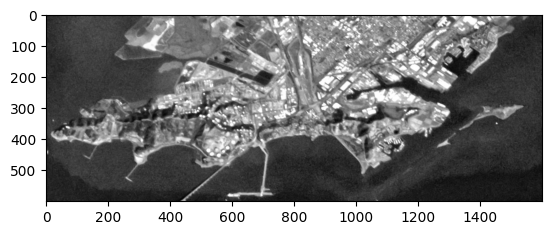

In [6]:
# we can make a cutout to work with a smaller part of the image (slicing)
cutout_RGB = img_RGB[0:600, 0:1600]
cutout_gray = cv2.cvtColor(cutout_RGB, cv2.COLOR_RGB2GRAY)
plt.imshow(cutout_gray, cmap='gray')
plt.show()

**TODO**: Flip the image horizontally and vertically and plot the results! Check out OpenCV's flip function for this task (see for example here: https://www.geeksforgeeks.org/python-opencv-cv2-flip-method/).

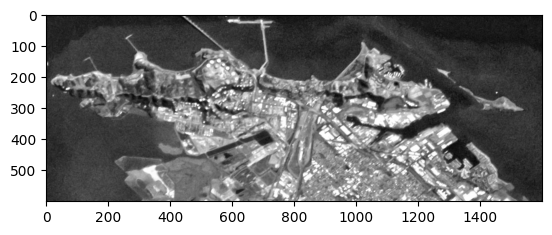

In [13]:
# YOUR CODE GOES HERE
flip_img = cv2.flip(cutout_gray, 0)

plt.imshow(flip_img, cmap='gray')
plt.show()


**TODO**: Draw a red rectangle around one of the bridges in the original image. Check the OpenCV documentation for a suitable function to use! Note that drawing on the image changes the original image, so make a copy first.

**HINT:** You can use several lines as seen in the demo, but maybe there is a simpler function?

**NOTE:** In NumPy, you accessed image pixels using

```python
image[row, column]
```

that is, first the vertical position (`y`), then the horizontal position (`x`).

OpenCV functions, however, expect point coordinates in the usual Cartesian order:

```python
(x, y)
```

So be careful: NumPy uses `(row, column) = (y, x)`, while OpenCV drawing functions use `(x, y)`.

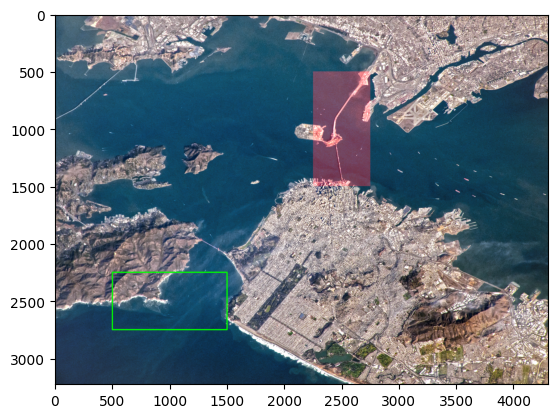

In [32]:
# YOUR CODE GOES HERE

blank_image = np.zeros(img_RGB.shape, np.uint8)

coordinates = [[(500, 1500), (2250, 2750)]]

for c in range(len(coordinates)):
    blank_image[
        coordinates[c][0][0]:coordinates[c][0][1],
        coordinates[c][1][0]:coordinates[c][1][1],
        2
    ] = 100

    img_RGB = cv2.rectangle(img_RGB,
                  (500, 2250),
                  (1500, 2750),
                  color=(0,255,0),
                  thickness=10)


blank_image = cv2.cvtColor(blank_image, cv2.COLOR_BGR2RGB)

new_image = cv2.add(blank_image, img_RGB)

plt.imshow(new_image)
plt.show()


**TODO**: Resize the result to 400x400 pixels. 

In [9]:
# YOUR CODE GOES HERE